# AeroFox — Comprehensive Analysis of NASA Microgravity Combustion Data

**NASA Space Apps Challenge 2026 · Flame in Freefall**

This notebook is the scientific investigation that AeroFox is built on. It answers five questions before any
software architecture is chosen:

1. What combustion data does NASA's Physical Sciences Informatics (PSI) repository actually hold, and how much of it is usable?
2. Which variables, units and experimental conditions are recorded, and where are the records inconsistent?
3. Which quantitative findings can be reproduced directly from the raw files?
4. Which engineering questions (cabin materials, ventilation, detection, suppression, exploration atmospheres, lunar and Martian habitats) does the evidence support, and which does it not?
5. What should an AI assistant built on this evidence be allowed to claim?

**How to run.** On Google Colab: *Runtime → Run all*. The first code cell installs the two extra packages that Colab
lacks and obtains the AeroFox data snapshot (from a local checkout, from the GitHub repository, or from an uploaded ZIP).
No API keys or private files are needed. Runtime on a standard CPU session is about one minute.

**Conventions.** SI units are used in derived columns (kPa, mm, mm² s⁻¹, cm s⁻¹). Raw values are kept next to cleaned
values. Every figure caption states its data source and unit of analysis. Status labels follow the AeroFox provenance scheme:
`verified_this_run`, `snapshot` (previously verified), `published` (literature statement) and `synthetic` (illustrative input).

## 0. Environment and data snapshot

In [1]:
import os, sys, json, subprocess, shutil, zipfile, io, re, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
AEROFOX_REPO = os.environ.get("AEROFOX_REPO", "").strip()

def find_root():
    for cand in [Path.cwd(), Path.cwd().parent, Path("/content/aerofox")]:
        if (cand / "data" / "processed" / "flex_tests.csv").exists():
            return cand.resolve()
    return None

ROOT = find_root()
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openpyxl", "xlrd"], check=True)
if ROOT is None and IN_COLAB:
    if AEROFOX_REPO:
        subprocess.run(["git", "clone", "--depth", "1", AEROFOX_REPO, "/content/aerofox"], check=False)
        ROOT = find_root()
    if ROOT is None:
        print("Upload the supplied AeroFox release ZIP.")
        from google.colab import files
        uploaded = files.upload()
        target = Path("/content").resolve()
        for name, data in uploaded.items():
            if not name.lower().endswith(".zip"):
                continue
            with zipfile.ZipFile(io.BytesIO(data)) as archive:
                for member in archive.infolist():
                    if not (target / member.filename).resolve().is_relative_to(target):
                        raise ValueError("Invalid path in the uploaded AeroFox ZIP")
                archive.extractall(target)
        ROOT = find_root()
assert ROOT is not None, "AeroFox data snapshot not found"
os.chdir(ROOT)
DATA, PROC = ROOT / "data", ROOT / "data" / "processed"
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "backend"))
print("AeroFox root:", ROOT)

AeroFox snapshot found.


In [2]:
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
                     "font.family": "serif"})
PALETTE = {"N2": "#1f4e79", "CO2": "#c55a11", "He": "#548235", "Methanol": "#1f4e79", "Heptane": "#c55a11"}
FIGS = []
def savefig(fig, name, caption):
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    FIGS.append({"file": f"outputs/figures/{name}.png", "caption": caption})
    plt.show()
def load(name):
    return pd.read_csv(PROC / f"{name}.csv")

manifest = json.loads((DATA / "raw" / "psi" / "manifest.json").read_text())
files = pd.DataFrame(manifest["files"]).T
print("Snapshot entries:", len(files))
print(files.groupby(["kind", "status"]).size().rename("n").to_string())
last = manifest["runs"][-1]
print("\nLast acquisition run:", last.get("started"), "->", last.get("finished"), "| ok", last.get("ok"),
      "| snapshot", last.get("snapshot"), "| missing", last.get("missing"))

Snapshot entries: 677
kind                    status           
experimentalTable       verified_this_run     22
file_catalog            verified_this_run     24
investigation_metadata  verified_this_run     24
raw_file                verified_this_run    603
raw_file_cached         verified_this_run      3
search_index            verified_this_run      1

Last acquisition run: 2026-11-14T22:11:59Z -> 2026-11-14T22:30:18Z | ok 677 | snapshot 0 | missing 0


**Provenance.** Every file in the snapshot is listed in `data/raw/psi/manifest.json` with source URL, SHA-256, size,
retrieval time and status. The acquisition code (`backend/aerofox/ingest/`) retries with bounded exponential backoff and
jitter, validates HTTP status and content type, writes atomically and never replaces a verified file with a failed
download. Large telemetry workbooks (Saffire I–III) are kept in a git-ignored cache; only their derived, compact
extracts are committed. To refresh from NASA (network required), run `python -m aerofox.ingest.psi_snapshot` and then
`python -m aerofox.ingest.derive` from `backend/`; the cell below re-verifies checksums offline.

In [3]:
import hashlib
def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for b in iter(lambda: fh.read(1 << 16), b""): h.update(b)
    return h.hexdigest()
check = []
for key, e in manifest["files"].items():
    p = ROOT / e["path"]
    if e.get("committed") is False:          # cached telemetry, not part of the repository
        check.append((key, "cache_only", p.exists() and sha(p) == e.get("sha256")))
    else:
        check.append((key, "repo", p.exists() and sha(p) == e.get("sha256")))
chk = pd.DataFrame(check, columns=["key", "location", "checksum_ok"])
print(chk.groupby("location").checksum_ok.agg(["size", "sum"]).rename(columns={"size": "files", "sum": "checksum_ok"}))

            files  checksum_ok
location                      
cache_only      3            0
repo          674          674


## 1. What PSI holds: the 24 combustion investigations

Unit of analysis: **one PSI investigation** (an accession such as PSI-69). The file catalog was retrieved through the PSI
JSON API (`/geode-py/ws/files/v2`) for every investigation, so counts below are of catalog entries, not of downloaded files.

In [4]:
inv = load("investigations")
cat = load("catalog_summary")
dlog = json.loads((PROC / "derivation_log.json").read_text())
cols = ["accession", "acronym", "project_type", "flight_program", "sub_research_area", "license",
        "n_experiment_tables", "catalog_files", "catalog_bytes", "n_publications"]
t1 = inv[cols].copy()
t1["catalog_GB"] = (t1.catalog_bytes / 1e9).round(1)
t1 = t1.drop(columns="catalog_bytes").sort_values("catalog_GB", ascending=False)
t1.to_csv(TAB / "T01_investigation_inventory.csv", index=False)
display(t1) if "display" in dir() else print(t1.to_string())
c = dlog["catalog"]
print(f"Catalog entries: {c['entries']:,}; unique object keys: {c['unique_keys']:,}; "
      f"referenced volume {c['referenced_bytes']/1e12:.2f} TB ({c['referenced_bytes_dedup_name_size']/1e12:.2f} TB after "
      f"removing duplicate name+size pairs).")
print("Investigations by type:", inv.project_type.value_counts().to_dict())
print("Licenses:", inv.license.value_counts().to_dict())

   accession              acronym                project_type                     flight_program                     sub_research_area      license  n_experiment_tables  catalog_files  n_publications  catalog_GB
0     PSI-10    ACME/Flame Design  Microgravity Investigation  International Space Station (ISS)               Flames of Gaseous Fuels  unspecified                    2           3807              33      2180.4
9    PSI-159           ACME CFI-G  Microgravity Investigation  International Space Station (ISS)               Flames of Gaseous Fuels      CC0-1.0                    2           3756               2      2085.6
10    PSI-20             ACME BRE  Microgravity Investigation  International Space Station (ISS)               Flames of Gaseous Fuels      CC0-1.0                    1           2361              16      2035.6
11    PSI-21       ACME CLD Flame  Microgravity Investigation  International Space Station (ISS)                Flames of gaseous fuel      CC0-1.0     

**Verification of the inherited audit.** An earlier audit reported ≈24 combustion investigations, 22 experiment tables,
66,567 catalog entries before deduplication (≈60,866 after) and ≈13.47 TB of referenced content. This run reproduces
24 investigations, 22 experiment tables and **exactly 66,567** catalog entries. Deduplicating by object key gives
60,797 entries (69 fewer than the inherited figure; the earlier deduplication rule was not documented, so the difference
cannot be attributed). The 13.47 TB figure matches the volume *after* removing duplicate objects; before deduplication the
catalog references 13.50 TB. **None of this volume has been downloaded**: the AeroFox snapshot holds about 40 MB of
tables, test sheets and droplet histories selected for analysis, plus ~44 MB of cached telemetry.

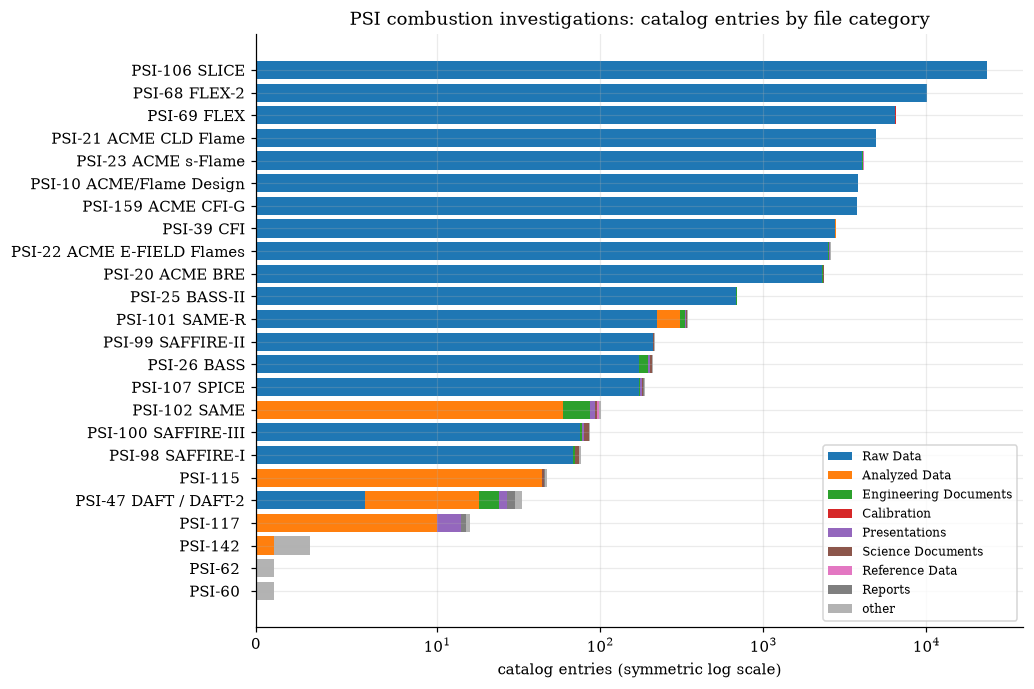

In [5]:
pv = cat.pivot_table(index="accession", columns="category", values="files", aggfunc="sum").fillna(0)
order = inv.set_index("accession").loc[pv.index].assign(lbl=lambda d: d.index + " " + d.acronym.fillna(""))
pv.index = order.lbl
pv = pv.loc[pv.sum(axis=1).sort_values().index]
main_cats = pv.sum().sort_values(ascending=False).index[:8]
fig, ax = plt.subplots(figsize=(9, 7))
left = np.zeros(len(pv))
for i, cname in enumerate(main_cats):
    ax.barh(pv.index, pv[cname], left=left, label=cname, color=plt.cm.tab10(i))
    left += pv[cname].values
other = pv.drop(columns=main_cats).sum(axis=1)
ax.barh(pv.index, other, left=left, label="other", color="0.7")
ax.set_xscale("symlog", linthresh=10); ax.set_xlabel("catalog entries (symmetric log scale)")
ax.legend(fontsize=8, loc="lower right"); ax.set_title("PSI combustion investigations: catalog entries by file category")
savefig(fig, "fig01_catalog_by_category",
        "Figure 1. Number of PSI catalog entries per combustion investigation, split by the PSI file category (third path "
        "component of the object key). Source: PSI /files/v2 catalog retrieved in this run. Unit: catalog entry.")

**Interpretation.** Volume is dominated by imagery and raw video from ACME, CFI-G and FLEX (each ≈1–2 TB). Ground
investigations (PSI-60, -62, -115, -117, -142) hold few files and mostly modelling products. The compact, analysis-ready
evidence — experiment tables, per-test sheets, droplet histories, telemetry and reduced aerosol data — is a very small
fraction of the archive, which is why AeroFox can carry a complete offline snapshot of it.

## 2. Data quality audit

Unit of analysis: **one column of one experiment table** (missingness), then individual records (specific defects).
"Missing" counts empty cells and the literal strings `none`, `n/a`, `nan`.

In [6]:
qa = load("quality_audit_columns")
qa_tables = qa[qa.table.str.startswith(("flex_tests", "cfi_tests", "saffire_samples", "bass2_tests", "same_r_tests", "table_"))]
summary = qa_tables.groupby("table").agg(columns=("column", "size"), rows=("rows", "max"),
                                          mean_missing_pct=("missing_pct", "mean")).round(1)
summary.to_csv(TAB / "T02_missingness_by_table.csv")
print(summary.sort_values("mean_missing_pct", ascending=False).to_string())

                                         columns  rows  mean_missing_pct
table                                                                   
cfi_tests                                     34    87              48.4
table_PSI-22_acme_e_field_flames              10    32              36.3
table_PSI-102_same                             5     8              30.0
saffire_samples                               23    13              18.7
same_r_tests                                  17   109              14.0
table_PSI-21_cld_flame                         8    32              12.1
table_PSI-20_acme_bre                          8    18              11.1
table_PSI-159_cfi_g_normal_flames             18   179               9.6
table_PSI-23_acme_s_flame                      9    18               9.3
bass2_tests                                   25   129               8.6
table_PSI-159_cfi_g_inverse_flames            20   154               4.1
flex_tests                                    62   

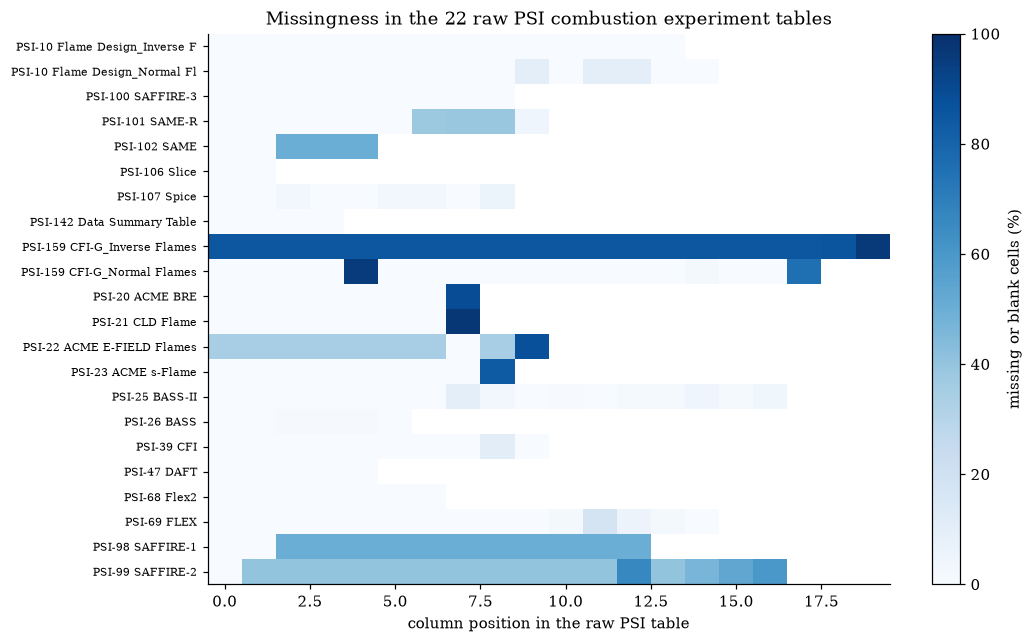

In [7]:
raw_tables = {}
for p in sorted((DATA / "raw" / "psi" / "tables").glob("*/*.csv")):
    try: df = pd.read_csv(p, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    except UnicodeDecodeError: df = pd.read_csv(p, dtype=str, keep_default_na=False, encoding="latin-1")
    raw_tables[p.parent.name + " " + p.stem.split("table_")[-1][:22]] = df
names = list(raw_tables)
maxc = max(df.shape[1] for df in raw_tables.values())
M = np.full((len(names), maxc), np.nan)
for i, n in enumerate(names):
    df = raw_tables[n]
    blank = df.apply(lambda s: s.str.strip().str.lower().isin(["", "none", "n/a", "nan"])).mean().values
    M[i, :len(blank)] = blank * 100
fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(M, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=7)
ax.set_xlabel("column position in the raw PSI table"); ax.grid(False)
plt.colorbar(im, label="missing or blank cells (%)")
ax.set_title("Missingness in the 22 raw PSI combustion experiment tables")
savefig(fig, "fig02_missingness_heatmap",
        "Figure 2. Percentage of empty/'none'/'n/a' cells per column in each raw PSI experiment table (grey = column does not "
        "exist). Source: data/raw/psi/tables. Unit: table column.")

### 2.1 Specific defects found and how they are handled

In [8]:
flex = load("flex_tests"); saf = load("saffire_samples"); b2 = load("bass2_tests")
issues = [
 ("PSI-69 FLEX", "'FLEX Test #' drifts from official FLEX numbering after test 155",
  f"{int((flex.table_number_offset != 0).sum())} of {len(flex)} rows offset by 1-6",
  "Re-keyed on CIR identifier using NASA/TP-2015-216046; column flex_number"),
 ("PSI-69 FLEX", "Burning-rate column labelled 'mm' (should be mm^2/s)", "all rows", "Interpreted as K in mm^2/s, confirmed by test sheets"),
 ("PSI-69 FLEX", "Ambient pressure of 0 mmHg for a burning test", f"{int(flex.flag_zero_pressure.sum())} row (CIR C11M201)", "Flagged; excluded from pressure analyses"),
 ("PSI-69 FLEX", "Composition columns labelled 'O', 'N', 'CO'", "header", "Interpreted as O2, N2, CO2 mole fractions"),
 ("PSI-99 Saffire-II", "Flow listed as 20 cm/s for sample 2-6", "1 row", "Telemetry and NTRS 20170008805 show 25 cm/s (Section 5)"),
 ("PSI-99 Saffire-II", "Thickness '037 mm'", "4 rows", "Read as 0.37 mm (NTRS 20170008805)"),
 ("PSI-99 Saffire-II", "Material blank for 2-6 and 2-9", "2 rows", "Filled from NTRS 20170008805 with provenance column"),
 ("PSI-99 Saffire-II", "O2 'derived from measured CO2 production' (table note 1)", "column", "Labelled as derived, not measured"),
 ("PSI-99 telemetry", "'RelativeSeconds' holds milliseconds", "column", "Divided by 1000"),
 ("PSI-98 Saffire-I", "Sample length/width appear transposed (40.6 x 94 cm)", "2 rows", "Stored as tabulated; noted"),
 ("PSI-25 BASS-II", "Final O2 above initial O2 by >1 vol%", f"{int(b2.flag_o2_increase.sum())} rows", "Flagged as implausible (no O2 source)"),
 ("PSI-25 BASS-II", "Multi-valued cells ('53   43', '2(?)') and 'none' strings",
  f"{int(b2.multi_valued_fan.sum())} fan cells", "Kept raw; numeric value NaN"),
 ("PSI-101 SAME", "Particle moments recorded as 0 when not measured", "DBP rows", "Treated as missing"),
]
issues = pd.DataFrame(issues, columns=["dataset", "issue", "extent", "handling"])
issues.to_csv(TAB / "T03_quality_issues.csv", index=False)
print(issues.to_string(index=False))

          dataset                                                            issue                        extent                                                                 handling
      PSI-69 FLEX 'FLEX Test #' drifts from official FLEX numbering after test 155 119 of 274 rows offset by 1-6 Re-keyed on CIR identifier using NASA/TP-2015-216046; column flex_number
      PSI-69 FLEX             Burning-rate column labelled 'mm' (should be mm^2/s)                      all rows                     Interpreted as K in mm^2/s, confirmed by test sheets
      PSI-69 FLEX                    Ambient pressure of 0 mmHg for a burning test           1 row (CIR C11M201)                                 Flagged; excluded from pressure analyses
      PSI-69 FLEX                      Composition columns labelled 'O', 'N', 'CO'                        header                                Interpreted as O2, N2, CO2 mole fractions
PSI-99 Saffire-II                            Flow listed as 20 cm/s fo

## 3. FLEX droplet combustion (PSI-69)

**Unit of analysis: one droplet test** (one ignition in the CIR/MDCA). Time samples inside a droplet history are not
replicates. The ambient is specified by total pressure *p*, O₂ mole fraction *X*<sub>O2</sub> and a diluent (N₂, CO₂ or He);
the O₂ partial pressure is *p*<sub>O2</sub> = *X*<sub>O2</sub>·*p*. The burning-rate constant *K* follows from the
d²-law, *d*²(*t*) = *d*₀² − *K t*.

In [9]:
f = flex[~flex.flag_zero_pressure].copy()
print("Tests:", len(flex), "| usable pressure:", len(f))
print(pd.crosstab([f.fuel, f.diluent], f.test_end, margins=True))
desc = f.groupby(["fuel", "diluent"]).agg(
    n=("flex_number", "size"), p_kPa_min=("p_kPa", "min"), p_kPa_max=("p_kPa", "max"),
    xO2_min=("x_o2", "min"), xO2_max=("x_o2", "max"), d0_mm_median=("d0_mm", "median"),
    K_mean=("K_mm2s", "mean"), K_sd=("K_mm2s", "std"), K_median=("K_mm2s", "median"),
    K_q1=("K_mm2s", lambda s: s.quantile(.25)), K_q3=("K_mm2s", lambda s: s.quantile(.75)),
    K_missing=("K_mm2s", lambda s: s.isna().sum())).round(3)
desc["K_cv"] = (desc.K_sd / desc.K_mean).round(2)
desc.to_csv(TAB / "T04_flex_descriptive.csv")
print(desc.to_string())

Tests: 274 | usable pressure: 273
test_end          Completion  Disruption  Extinction  All
fuel     diluent                                         
Heptane  CO2               3          15          24   42
         He                5           2          14   21
         N2               11          21          22   54
Methanol CO2               5           9          54   68
         He                0           2          24   26
         N2                3          12          47   62
All                       27          61         185  273
                   n  p_kPa_min  p_kPa_max  xO2_min  xO2_max  d0_mm_median  K_mean   K_sd  K_median   K_q1   K_q3  K_missing  K_cv
fuel     diluent                                                                                                                  
Heptane  CO2      42     70.808    309.295     0.17     0.25         2.905   0.466  0.130      0.50  0.365  0.560          3  0.28
         He       21     70.394    102.192     0.16

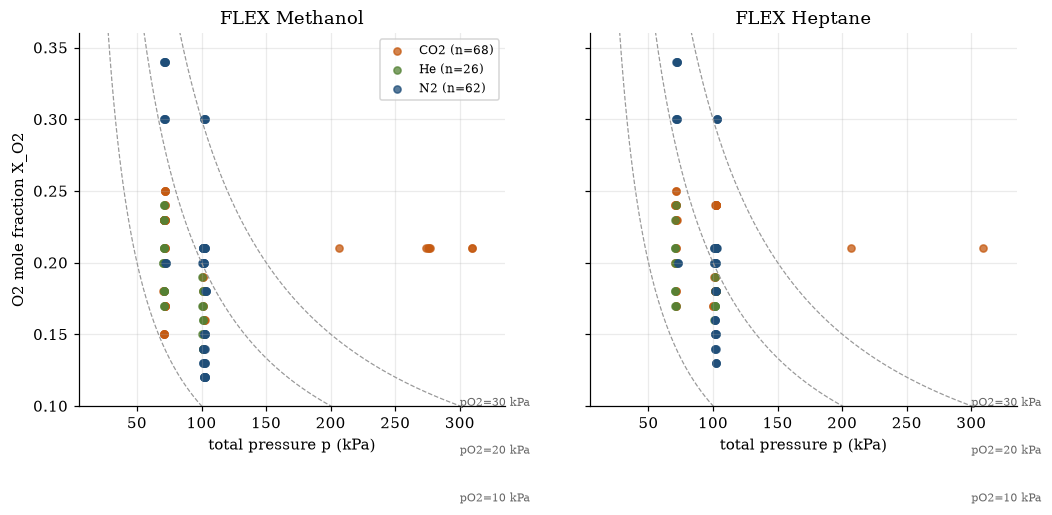

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for a, fuel in zip(ax, ["Methanol", "Heptane"]):
    d = f[f.fuel == fuel]
    for dil, g in d.groupby("diluent"):
        a.scatter(g.p_kPa, g.x_o2, s=22, alpha=.75, label=f"{dil} (n={len(g)})", color=PALETTE.get(dil))
    pp = np.linspace(20, 320, 200)
    for po2 in [10, 20, 30]:
        a.plot(pp, po2 / pp, color="0.6", lw=.8, ls="--"); a.text(300, po2 / 300, f"pO2={po2} kPa", fontsize=7, color="0.4")
    a.set_xlabel("total pressure p (kPa)"); a.set_title(f"FLEX {fuel}"); a.set_ylim(0.1, 0.36)
ax[0].set_ylabel("O2 mole fraction X_O2"); ax[0].legend(fontsize=8)
savefig(fig, "fig03_flex_condition_map",
        "Figure 3. Ambient conditions of FLEX tests by fuel and diluent; dashed lines are constant O2 partial pressure. "
        "Source: PSI-69 experiment table (test with 0 mmHg excluded). Unit: droplet test.")

**Interpretation.** The FLEX design is not a factorial grid: CO₂ and He dilution were explored mainly near 1 atm, and
*X*<sub>O2</sub> was lowered in steps toward extinction. Pressure and diluent are therefore partly confounded, and any
comparison across diluents must control for *X*<sub>O2</sub> and pressure.

### 3.1 Independent verification of the tabulated burning-rate constants

Fits with R^2 > 0.95: 206 of 247 fitted histories
Median difference (fit - table): -0.0011 mm^2/s; IQR [-0.0069, +0.0069]
Pearson r with CIR-based join: 0.987; with PSI table numbering: 0.729 (n=197)


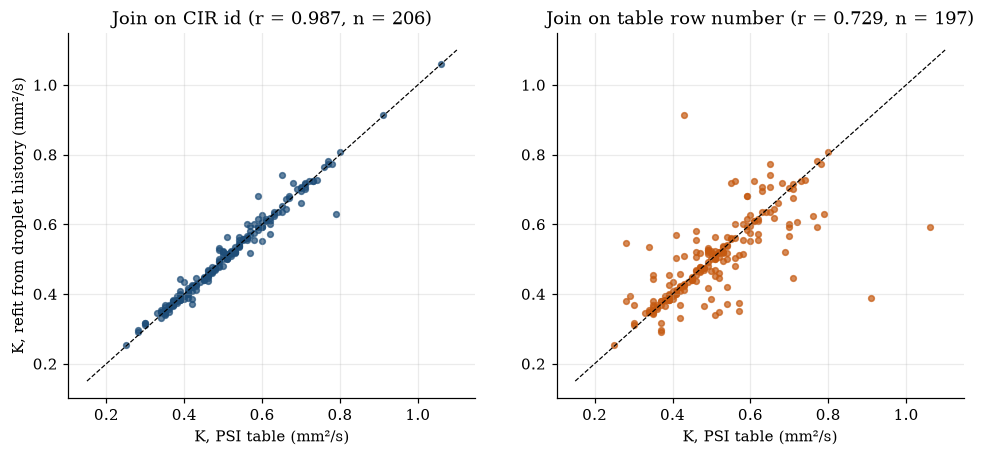

In [11]:
fits = load("flex_droplet_fits")
v = f[(f.K_fit_r2 > 0.95) & f.K_mm2s.notna()].copy()
diff = v.K_fit_mm2s - v.K_mm2s
# what the same comparison looks like if files are joined by the PSI table's row number
fits_by_num = fits.set_index("flex_number")
naive = flex.join(fits_by_num[["K_fit_mm2s", "K_fit_r2"]], on="test", rsuffix="_naive")
nv = naive[(naive.K_fit_r2_naive > 0.95) & naive.K_mm2s.notna()]
r_ok, r_naive = np.corrcoef(v.K_fit_mm2s, v.K_mm2s)[0, 1], np.corrcoef(nv.K_fit_mm2s_naive, nv.K_mm2s)[0, 1]
print(f"Fits with R^2 > 0.95: {len(v)} of {fits.K_fit_mm2s.notna().sum()} fitted histories")
print(f"Median difference (fit - table): {diff.median():+.4f} mm^2/s; IQR [{diff.quantile(.25):+.4f}, {diff.quantile(.75):+.4f}]")
print(f"Pearson r with CIR-based join: {r_ok:.3f}; with PSI table numbering: {r_naive:.3f} (n={len(nv)})")
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.3))
ax[0].scatter(v.K_mm2s, v.K_fit_mm2s, s=14, alpha=.7, color="#1f4e79")
lim = [0.15, 1.1]; ax[0].plot(lim, lim, "k--", lw=.8)
ax[0].set_xlabel("K, PSI table (mm²/s)"); ax[0].set_ylabel("K, refit from droplet history (mm²/s)")
ax[0].set_title(f"Join on CIR id (r = {r_ok:.3f}, n = {len(v)})")
ax[1].scatter(nv.K_mm2s, nv.K_fit_mm2s_naive, s=14, alpha=.7, color="#c55a11")
ax[1].plot(lim, lim, "k--", lw=.8); ax[1].set_xlabel("K, PSI table (mm²/s)")
ax[1].set_title(f"Join on table row number (r = {r_naive:.3f}, n = {len(nv)})")
savefig(fig, "fig04_flex_k_verification",
        "Figure 4. Burning-rate constant from the PSI table versus an independent OLS fit of d² against t on 0.2–0.9 of the "
        "visible burn time of each raw droplet history. Left: files matched through the CIR identifier and NASA/TP-2015-216046 "
        "numbering. Right: files matched by the table's row number. Unit: droplet test.")

**Interpretation.** Refitting *K* from 1,000+ diameter measurements per test reproduces the tabulated values to within
±0.007 mm² s⁻¹ (interquartile range) — but only after the records are matched correctly. Joining the PSI table to the
per-test files by its "FLEX Test #" pairs more than 40% of the tests with the wrong droplet history. This is a concrete
reproducibility hazard for anyone (or any AI system) consuming the PSI table directly; AeroFox uses the corrected key.

### 3.2 How *K* depends on oxygen, pressure and diluent

In [12]:
def ols(X, y):
    beta, *_ = np.linalg.lstsq(X, y, rcond=None); return beta
rng = np.random.default_rng(20261114)
rows = []
for fuel, d in f.dropna(subset=["K_mm2s", "x_o2", "p_kPa"]).groupby("fuel"):
    d = d[d.p_kPa > 0]
    X = np.column_stack([np.ones(len(d)), d.x_o2, np.log(d.p_kPa / 101.325),
                         (d.diluent == "CO2").astype(float), (d.diluent == "He").astype(float)])
    y = d.K_mm2s.values
    b = ols(X, y)
    boot = np.array([ols(X[i], y[i]) for i in (rng.integers(0, len(d), len(d)) for _ in range(2000))])
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    resid = y - X @ b; r2 = 1 - resid.var() / y.var()
    for name, bi, l, h in zip(["intercept", "X_O2", "ln(p/1 atm)", "CO2 vs N2", "He vs N2"], b, lo, hi):
        rows.append({"fuel": fuel, "term": name, "coef": bi, "ci95_lo": l, "ci95_hi": h, "n_tests": len(d), "R2": r2})
reg = pd.DataFrame(rows).round(3)
reg.to_csv(TAB / "T05_flex_K_regression.csv", index=False)
print(reg.to_string(index=False))
print("\nCorrelation of X_O2 with diluent=He / CO2 indicator (methanol):",
      f[f.fuel=="Methanol"].assign(he=lambda d: (d.diluent=="He")*1, co2=lambda d:(d.diluent=="CO2")*1)[["x_o2","he","co2"]].corr().round(2).iloc[0,1:].to_dict())

    fuel        term   coef  ci95_lo  ci95_hi  n_tests    R2
 Heptane   intercept  0.159    0.012    0.341      107 0.418
 Heptane        X_O2  1.918    1.170    2.569      107 0.418
 Heptane ln(p/1 atm)  0.080   -0.087    0.201      107 0.418
 Heptane   CO2 vs N2 -0.085   -0.135   -0.041      107 0.418
 Heptane    He vs N2  0.144    0.060    0.228      107 0.418
Methanol   intercept  0.146    0.108    0.180      150 0.791
Methanol        X_O2  1.621    1.420    1.829      150 0.791
Methanol ln(p/1 atm)  0.009   -0.028    0.058      150 0.791
Methanol   CO2 vs N2 -0.034   -0.051   -0.016      150 0.791
Methanol    He vs N2  0.144    0.119    0.171      150 0.791

Correlation of X_O2 with diluent=He / CO2 indicator (methanol): {'he': -0.11, 'co2': -0.01}


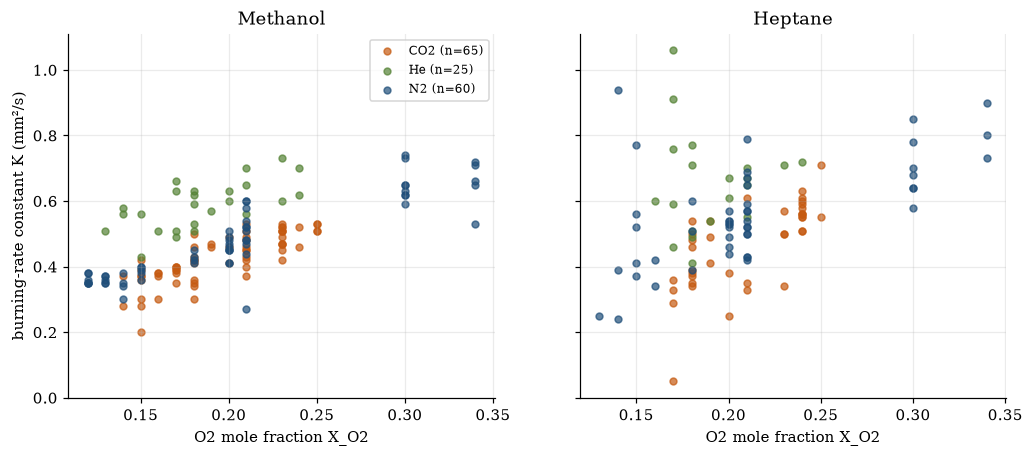

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for a, fuel in zip(ax, ["Methanol", "Heptane"]):
    d = f[(f.fuel == fuel) & f.K_mm2s.notna()]
    for dil, g in d.groupby("diluent"):
        a.scatter(g.x_o2, g.K_mm2s, s=20, alpha=.7, color=PALETTE.get(dil), label=f"{dil} (n={len(g)})")
    a.set_xlabel("O2 mole fraction X_O2"); a.set_title(fuel)
ax[0].set_ylabel("burning-rate constant K (mm²/s)"); ax[0].legend(fontsize=8)
savefig(fig, "fig05_flex_k_vs_o2",
        "Figure 5. FLEX burning-rate constant versus ambient O2 mole fraction, by diluent. Source: PSI-69 table (K) re-keyed "
        "to official FLEX numbering. Unit: droplet test. Regression coefficients with bootstrap 95% intervals (2,000 "
        "resamples of tests) are in Table T05.")

**Interpretation.** Within each fuel, *K* rises with *X*<sub>O2</sub>, as expected from the d²-law (*K* ∝ ln(1+*B*),
with the transfer number *B* increasing with ambient oxygen). Helium dilution gives markedly higher *K* than nitrogen at
the same *X*<sub>O2</sub>, consistent with helium's larger thermal diffusivity; CO₂ gives lower *K*. The regression is
descriptive: tests were not randomised, droplets of different initial size are pooled, and the bootstrap intervals
reflect only between-test scatter, not measurement uncertainty in *K* (not reported in PSI).

### 3.3 Extinction behaviour

test_end          Completion  Disruption  Extinction
fuel     diluent                                    
Heptane  CO2            0.07        0.36        0.57
         He             0.24        0.10        0.67
         N2             0.20        0.39        0.41
Methanol CO2            0.07        0.13        0.79
         He             0.00        0.08        0.92
         N2             0.05        0.19        0.76


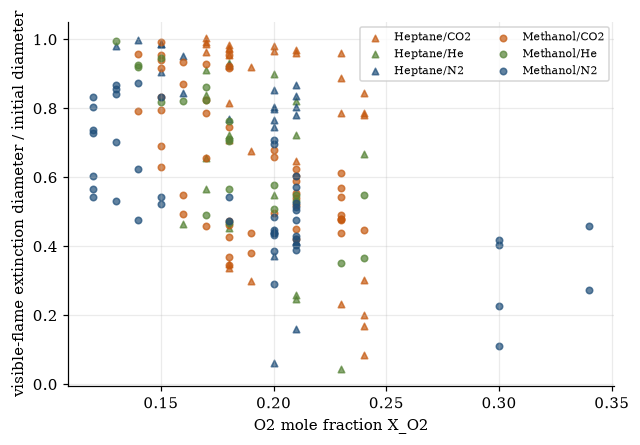

Spearman rho (X_O2 vs dext/d0): {'Heptane': -0.49, 'Methanol': -0.64}


In [14]:
e = f[f.d0_mm.notna() & f.dext_mm.notna() & (f.dext_mm > 0)].copy()
e["dext_over_d0"] = e.dext_mm / e.d0_mm
out = f.groupby(["fuel", "diluent"]).test_end.value_counts(normalize=True).unstack().fillna(0).round(2)
print(out)
fig, ax = plt.subplots(figsize=(6.4, 4.3))
for (fuel, dil), g in e.groupby(["fuel", "diluent"]):
    ax.scatter(g.x_o2, g.dext_over_d0, s=18, alpha=.7, marker="o" if fuel == "Methanol" else "^",
               color=PALETTE.get(dil), label=f"{fuel}/{dil}")
ax.set_xlabel("O2 mole fraction X_O2"); ax.set_ylabel("visible-flame extinction diameter / initial diameter")
ax.legend(fontsize=7, ncol=2)
savefig(fig, "fig06_flex_extinction_ratio",
        "Figure 6. Ratio of visible-flame extinction diameter to initial droplet diameter versus X_O2 for FLEX tests that ended "
        "in extinction with a measured diameter. Source: PSI-69 table. Unit: droplet test.")
print("Spearman rho (X_O2 vs dext/d0):", e.groupby("fuel").apply(lambda g: g.x_o2.corr(g.dext_over_d0, method="spearman")).round(2).to_dict())

**Interpretation.** Lower oxygen produces extinction at larger fractions of the initial diameter — the flame is lost
earlier. This is the microgravity signature of radiative extinction: without buoyancy the flame stands far from the
droplet, radiative loss grows with flame size, and a large droplet in dilute oxygen cannot sustain combustion. For
engineering use the corollary is that **visible extinction is not proof that combustion has stopped** (Section 4).

## 4. Case B — FLEX-035: what happens after the visible flame goes out

FLEX-035 (CIR 181F001, 27 Nov 2009): free-floating heptane droplet in air (*X*<sub>O2</sub> = 0.21, N₂ balance) at
102.4 kPa. Data: `FLEX-035_DropletData.txt` (droplet diameter, 30 Hz) and `FLEX-035_LLUVData.txt` (UV-camera flame
emission), both from PSI-69.

In [15]:
s = load("flex035_timeseries")
row = flex[flex.flex_number == 35].iloc[0]
tb = row.burn_time_s
burn = s[(s.t_s >= 0.2 * tb) & (s.t_s <= 0.9 * tb)]
post = s[(s.t_s >= tb + 0.5) & (s.t_s <= tb + 0.5 + 0.5 * tb)]
def fit(d):
    A = np.column_stack([np.ones(len(d)), d.t_s]); b, res, *_ = np.linalg.lstsq(A, d.d2_mm2, rcond=None)
    r = d.d2_mm2 - A @ b; se = np.sqrt(r.var(ddof=2) / ((d.t_s - d.t_s.mean())**2).sum())
    return -b[1], se, 1 - r.var() / d.d2_mm2.var(), b
K_b, se_b, r2_b, bb = fit(burn); K_p, se_p, r2_p, bp = fit(post)
# when does regression stop? rolling slope of d^2 over 2 s windows after extinction
late = s[(s.t_s > tb) & (s.t_s < 38.0)].copy()   # t > 38 s: imaging artifact (see text)
late["slope"] = late.d2_mm2.rolling(61, center=True).apply(lambda y: -np.polyfit(np.arange(len(y)) / 30.0, y, 1)[0], raw=True)
plateau_t = late[(late.slope < 0.1 * K_b) & (late.t_s > tb + 2)].t_s.min()
print(f"Tabulated: d0={row.d0_mm} mm, K={row.K_mm2s} mm^2/s, visible burn time tb={tb} s, d_ext={row.dext_mm} mm")
print(f"Fit while burning (0.2-0.9 tb): K = {K_b:.3f} ± {se_b:.3f} mm^2/s (R^2={r2_b:.3f}, n={len(burn)})")
print(f"Fit after visible extinction (tb+0.5 .. tb+0.5+0.5tb): K_post = {K_p:.3f} ± {se_p:.3f} mm^2/s (R^2={r2_p:.3f}, n={len(post)})")
print(f"Ratio K_post/K_burn = {K_p/K_b:.2f}; regression slows below 10% of K_burn at t ≈ {plateau_t:.1f} s "
      f"({plateau_t - tb:.1f} s after visible extinction)")
d_ext_pred = np.sqrt(row.d0_mm**2 - row.K_mm2s * tb)
print(f"Consistency: sqrt(d0^2 - K tb) = {d_ext_pred:.2f} mm vs tabulated extinction diameter {row.dext_mm} mm")
FLEX035 = dict(K_b=K_b, se_b=se_b, K_p=K_p, se_p=se_p, plateau_t=plateau_t, tb=tb, ratio=K_p / K_b)

Tabulated: d0=3.85 mm, K=0.43 mm^2/s, visible burn time tb=8.9 s, d_ext=3.34 mm
Fit while burning (0.2-0.9 tb): K = 0.412 ± 0.004 mm^2/s (R^2=0.986, n=181)
Fit after visible extinction (tb+0.5 .. tb+0.5+0.5tb): K_post = 0.419 ± 0.003 mm^2/s (R^2=0.995, n=128)
Ratio K_post/K_burn = 1.02; regression slows below 10% of K_burn at t ≈ 36.1 s (27.2 s after visible extinction)
Consistency: sqrt(d0^2 - K tb) = 3.32 mm vs tabulated extinction diameter 3.34 mm


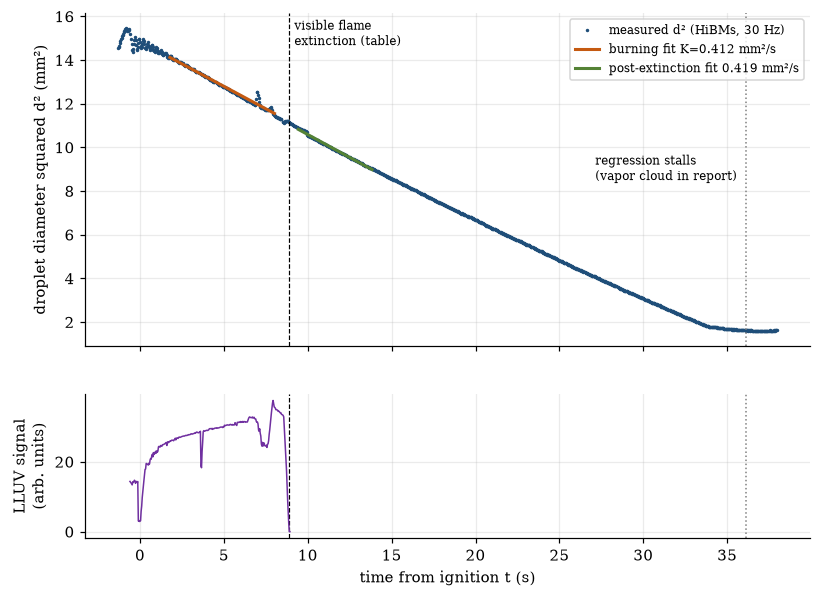

In [16]:
fig, ax = plt.subplots(2, 1, figsize=(8.5, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
s_plot = s[s.t_s < 38.0]
ax[0].plot(s_plot.t_s, s_plot.d2_mm2, ".", ms=2.5, color="#1f4e79", label="measured d² (HiBMs, 30 Hz)")
tt = np.linspace(0.2 * tb, 0.9 * tb, 10); ax[0].plot(tt, bb[0] + bb[1] * tt, color="#c55a11", lw=2, label=f"burning fit K={K_b:.3f} mm²/s")
tt = np.linspace(post.t_s.min(), post.t_s.max(), 10); ax[0].plot(tt, bp[0] + bp[1] * tt, color="#548235", lw=2, label=f"post-extinction fit {K_p:.3f} mm²/s")
for a in ax:
    a.axvline(tb, color="k", ls="--", lw=.8)
    a.axvline(plateau_t, color="0.5", ls=":", lw=1)
ax[0].text(tb + .3, s_plot.d2_mm2.max() * .95, "visible flame\nextinction (table)", fontsize=8)
ax[0].text(plateau_t - 9, s_plot.d2_mm2.max() * .55, "regression stalls\n(vapor cloud in report)", fontsize=8)
ax[0].set_ylabel("droplet diameter squared d² (mm²)"); ax[0].legend(fontsize=8, loc="upper right")
lu = s.dropna(subset=["lluv"])
ax[1].plot(lu.t_s, lu.lluv, color="#7030a0", lw=1); ax[1].set_ylabel("LLUV signal\n(arb. units)")
ax[1].set_xlabel("time from ignition t (s)")
savefig(fig, "fig07_flex035",
        "Figure 7. FLEX-035 (heptane, air, 102.4 kPa). Top: measured d² with OLS fits during visible burning and after visible "
        "extinction. Bottom: UV (LLUV) camera signal as provided in PSI (sparser sampling). Vertical dashed line: tabulated "
        "visible burn time; dotted line: time when the rolling regression rate first falls below 10% of K. Source: PSI-69 raw files.")

**Observation vs interpretation.**
*Observed (this notebook):* after the visible flame disappears the droplet keeps shrinking linearly in d² at a rate
statistically indistinguishable from the burning rate, for roughly 25 s, and then the regression stalls. The last
samples (t > 38 s), where the apparent diameter jumps, are an imaging artifact (the vapor cloud obscures the droplet)
and are not plotted or fitted.
*Published interpretation (NASA/TP-2015-216046, Fig. 39):* this is cool-flame burning followed by cool-flame extinction;
the stall coincides with a large vapor cloud. The droplet history alone cannot prove a cool flame (no species or
temperature data are in the snapshot), so AeroFox reports it as a literature interpretation consistent with the data.

**Engineering implication.** An optical (visible or UV) flame detector would declare this fire out while the fuel is
still reacting and releasing vapor. For liquid-fuel hazards in spacecraft, "flame out" should not by itself end a
suppression or ventilation-isolation response.

## 5. Case A — Saffire-II: tabulated versus measured ventilation

Saffire-II burned nine 5 cm × 29 cm samples in a flow duct inside an unoccupied Cygnus vehicle (November 2016).
**Unit of analysis: one sample burn.** Measured flow comes from the two duct anemometers in the PSI telemetry workbook
(1 Hz); each sample's ignition time is the first sample at which its igniter-current channel leaves its baseline state.

In [17]:
sf = load("saffire2_flow"); s2 = saf[saf.experiment == "Saffire-II"].merge(sf, on="sample")
cmp = s2[["sample", "material", "thickness_mm", "direction", "flow_nominal_cm_s", "anem1_mean_cm_s", "anem2_mean_cm_s",
          "anem_mean_cm_s", "anem_diff_cm_s", "burn_time_s", "ug_spread_rate_mm_s"]].round(2)
cmp["published_flow_cm_s"] = np.where(cmp["sample"] == "2-6", 25, 20)
cmp["table_minus_measured"] = (cmp.flow_nominal_cm_s - cmp.anem_mean_cm_s).round(2)
cmp.to_csv(TAB / "T06_saffire2_flow_comparison.csv", index=False)
print(cmp.to_string(index=False))

sample                  material  thickness_mm  direction  flow_nominal_cm_s  anem1_mean_cm_s  anem2_mean_cm_s  anem_mean_cm_s  anem_diff_cm_s  burn_time_s  ug_spread_rate_mm_s  published_flow_cm_s  table_minus_measured
   2-1                  Silicone          0.27 Concurrent               20.0            19.92            20.10           20.01           -0.18          NaN                  NaN                   20                 -0.01
   2-2                  Silicone          0.61 Concurrent               20.0            19.96            20.05           20.00           -0.09          NaN                  NaN                   20                  0.00
   2-3                  Silicone          1.03 Concurrent               20.0            19.97            20.04           20.01           -0.07          NaN                  NaN                   20                 -0.01
   2-4                  Silicone          0.37    Opposed               20.0            19.98            20.03          

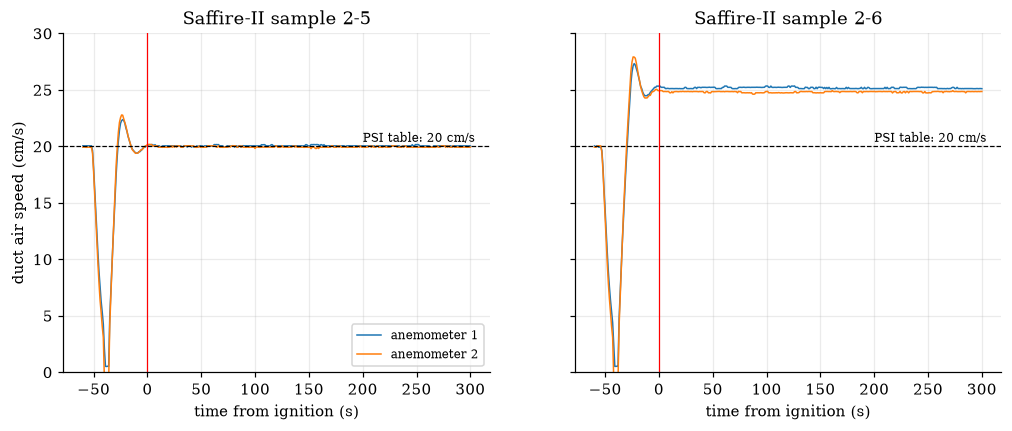

Burn-time consistency: 29 cm / 2.1 mm/s = 138 s (table 145 s); 29 cm / 2.6 mm/s = 112 s (table 115 s)
Spread-rate ratio 2-6/2-5 = 1.24; measured-flow ratio = 1.25


In [18]:
tw = load("saffire2_telemetry_windows")
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, smp in zip(ax, ["2-5", "2-6"]):
    w = tw[tw["sample"] == smp]
    a.plot(w.t_rel_s, w.Anemometer1, lw=1, label="anemometer 1"); a.plot(w.t_rel_s, w.Anemometer2, lw=1, label="anemometer 2")
    a.axhline(20, color="k", ls="--", lw=.8); a.text(200, 20.4, "PSI table: 20 cm/s", fontsize=8)
    a.axvline(0, color="r", lw=.8); a.set_title(f"Saffire-II sample {smp}"); a.set_xlabel("time from ignition (s)")
    a.set_ylim(0, 30)
ax[0].set_ylabel("duct air speed (cm/s)"); ax[0].legend(fontsize=8, loc="lower right")
savefig(fig, "fig08_saffire2_flow",
        "Figure 8. Duct anemometer readings around ignition (red line) for Saffire-II samples 2-5 and 2-6. Source: PSI-99 "
        "telemetry workbook (RawData sheet, 1 Hz), extracted to data/processed/saffire2_telemetry_windows.csv.")
r5, r6 = cmp.set_index("sample").loc["2-5"], cmp.set_index("sample").loc["2-6"]
L = 29.0
print(f"Burn-time consistency: 29 cm / {r5.ug_spread_rate_mm_s} mm/s = {L*10/r5.ug_spread_rate_mm_s:.0f} s (table {r5.burn_time_s:.0f} s); "
      f"29 cm / {r6.ug_spread_rate_mm_s} mm/s = {L*10/r6.ug_spread_rate_mm_s:.0f} s (table {r6.burn_time_s:.0f} s)")
print(f"Spread-rate ratio 2-6/2-5 = {r6.ug_spread_rate_mm_s/r5.ug_spread_rate_mm_s:.2f}; measured-flow ratio = {r6.anem_mean_cm_s/r5.anem_mean_cm_s:.2f}")
SAF = dict(flow5=r5.anem_mean_cm_s, flow6=r6.anem_mean_cm_s, v5=r5.ug_spread_rate_mm_s, v6=r6.ug_spread_rate_mm_s)

**Finding.** The PSI table lists 20 cm/s for every Saffire-II sample. The duct anemometers agree with that for samples
2-1 to 2-5, 2-7 and 2-8 (19.9–20.1 cm/s), but **sample 2-6 burned at ≈25 cm/s** (25.2 and 24.8 cm/s on the two
anemometers), which is what the NTRS presentation 20170008805 states. Samples 2-5 and 2-6 are the only replicate pair
of the same fabric: read from the table they look like two runs at identical conditions whose spread rates differ by 24%;
with the measured flow, the faster spread at 2-6 coincides with a 25% higher concurrent flow.

**Limits.** With one sample per flow speed this cannot separate a flow effect from run-to-run variability, and spread
rates have no reported uncertainty. Sample 2-9 shows a 3 cm/s disagreement between the two anemometers, so local flow
non-uniformity of that order should be assumed when using these data for model validation.

In [19]:
s_all = saf.copy()
s_all["area_cm2"] = s_all.length_cm * s_all.width_cm
print(s_all[["experiment", "sample", "material", "thickness_mm", "length_cm", "width_cm", "area_cm2",
             "flow_nominal_cm_s", "direction", "o2_pct", "burn_time_s", "ignition_energy_J"]].to_string(index=False))

 experiment sample                  material  thickness_mm  length_cm  width_cm  area_cm2  flow_nominal_cm_s  direction  o2_pct  burn_time_s  ignition_energy_J
  Saffire-I     S1              SIBAL Fabric          3.70       40.6      94.0    3816.4               20.0 Concurrent    21.5        420.0             1456.0
  Saffire-I     S2              SIBAL Fabric          3.70       40.6      94.0    3816.4               20.0    Opposed    21.5         70.0             1456.0
 Saffire-II    2-1                  Silicone          0.27       29.0       5.0     145.0               20.0 Concurrent    21.5          NaN              736.0
 Saffire-II    2-2                  Silicone          0.61       29.0       5.0     145.0               20.0 Concurrent    22.1          NaN              736.0
 Saffire-II    2-3                  Silicone          1.03       29.0       5.0     145.0               20.0 Concurrent    22.1          NaN              736.0
 Saffire-II    2-4                  Sili

Saffire I and III burned 0.94 m × 0.406 m SIBAL sheets — two orders of magnitude larger in area than earlier space
experiments — at 20 and 30 cm/s respectively. The PSI tables contain no spread rates for these large samples; quantitative
large-scale growth data must be taken from the published analyses (e.g. NTRS 20170008805: flame base and pyrolysis positions).

## 6. Case D — BASS-II solid-fuel burning and suppression (PSI-25)

**Unit: one BASS-II test point** in the Microgravity Science Glovebox (MSG). O₂ and CO₂ are calibrated vol% from the
CSA-CP analyser; N₂ dilution of the MSG work volume was used to lower O₂ (NTRS 20210011385).

Test points: 129 | PIs: {"T'ien": 29, 'Olson': 27, 'Fernandez-Pello': 27, 'Bhattacharjee': 22, 'Miller': 20, 'Ferkul': 4}
Material classes: {'other': 57, 'PMMA': 41, 'SIBAL': 27, 'film (unspecified)': 4}
       o2_init_pct  o2_final_pct  o2_drop_pct  co_final_ppm
count       127.00        125.00       125.00        118.00
mean         18.54         17.59         0.96        194.65
std           2.30          3.41         3.08        218.83
min          13.60          0.60        -0.10          0.30
25%          16.95         16.50         0.10         35.50
50%          18.00         17.40         0.30         94.00
75%          20.80         19.80         0.80        316.50
max          22.20         22.20        20.60        950.00


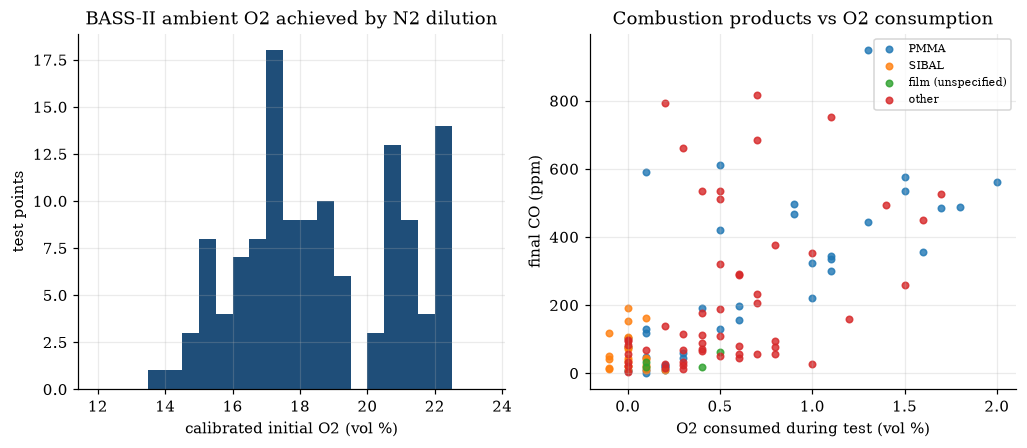

Spearman rho(O2 drop, final CO) = 0.63 n = 118


In [20]:
b = b2.copy()
ok = b[~b.flag_o2_increase]
print("Test points:", len(b), "| PIs:", b.pi.value_counts().to_dict())
print("Material classes:", b.material_class.value_counts().to_dict())
print(ok[["o2_init_pct", "o2_final_pct", "o2_drop_pct", "co_final_ppm"]].describe().round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hist(ok.o2_init_pct.dropna(), bins=np.arange(12, 24, 0.5), color="#1f4e79")
ax[0].set_xlabel("calibrated initial O2 (vol %)"); ax[0].set_ylabel("test points")
ax[0].set_title("BASS-II ambient O2 achieved by N2 dilution")
m = ok.dropna(subset=["o2_drop_pct", "co_final_ppm"])
for cls, g in m.groupby("material_class"):
    ax[1].scatter(g.o2_drop_pct, g.co_final_ppm, s=18, label=cls, alpha=.8)
ax[1].set_xlabel("O2 consumed during test (vol %)"); ax[1].set_ylabel("final CO (ppm)"); ax[1].legend(fontsize=7)
ax[1].set_title("Combustion products vs O2 consumption")
savefig(fig, "fig09_bass2",
        "Figure 9. BASS-II: distribution of calibrated initial O2 and final CO versus O2 drop per test point (points with "
        "physically implausible O2 increase excluded). Source: PSI-25 experiment table. Unit: test point.")
print("Spearman rho(O2 drop, final CO) =", round(m.o2_drop_pct.corr(m.co_final_ppm, method="spearman"), 2), "n =", len(m))

**Interpretation.** BASS-II spans roughly 15–22 vol% O₂, i.e. from cabin air down toward the limiting conditions of
the thin fuels tested. The table records conditions and gas composition, not flame spread or extinction outcome; those
are in the video archive and the NASA TM. AeroFox therefore uses BASS-II as **evidence of tested conditions** and cites
the TM for extinction limits rather than computing limits it cannot reproduce.

## 7. Case C — Smoke detection: SAME and SAME-R (PSI-101/102)

**Unit: one smoke-generation test** (a heated, non-flaming material sample). Particle moments are from the reduced data
sheet of the PSI-101 results workbook; detector responses from its "SAME R Results" sheet.

                  n  AMD_median_um     q1     q3
flight material                                 
SAME   Kapton     6          0.159  0.124  0.205
       Lampwick   6          0.236  0.174  0.274
       Silicone   7          0.227  0.207  0.301
       Teflon     6          0.180  0.159  0.186
SAME-R Kapton    27          0.112  0.075  0.155
       Lampwick  20          0.177  0.129  0.232
       Pyrell    20          0.302  0.229  0.359
       Silicone  22          0.362  0.243  0.452
       Teflon    17          0.172  0.140  0.267


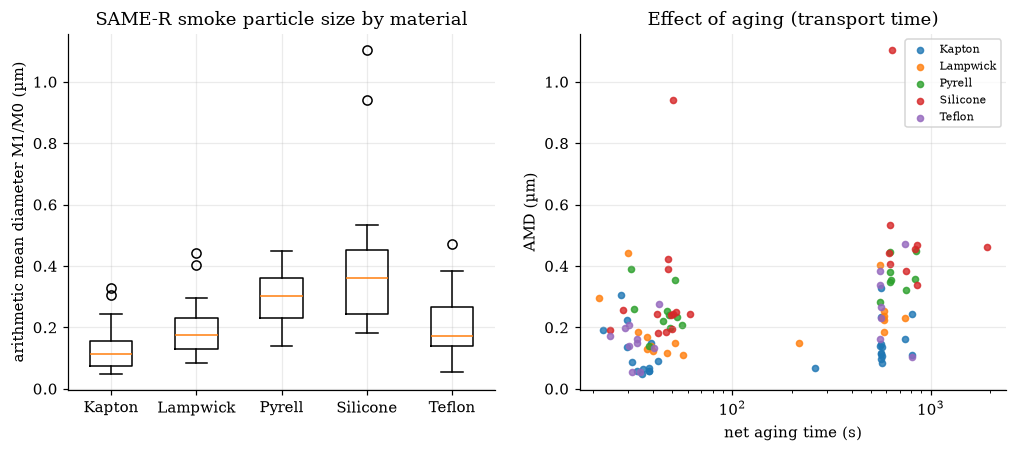

Spearman rho(AMD, aging) by material: {'Kapton': 0.19, 'Lampwick': 0.15, 'Pyrell': 0.54, 'Silicone': 0.67, 'Teflon': 0.32}
ISS smoke detector scatter channel: median 6.22 V, 50% of tests >= 6.2 V (max 6.28 V); STS detector used in 17 of 109 tests


In [21]:
sr = load("same_reduced"); det = load("same_r_detectors")
same_tab = sr.dropna(subset=["amd_um"]).groupby(["flight", "material"]).amd_um.agg(["count", "median",
      lambda x: x.quantile(.25), lambda x: x.quantile(.75)]).round(3)
same_tab.columns = ["n", "AMD_median_um", "q1", "q3"]; same_tab.to_csv(TAB / "T07_same_particle_size.csv"); print(same_tab)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
mats = sorted(sr[sr.flight == "SAME-R"].dropna(subset=["amd_um"]).material.unique())
ax[0].boxplot([sr[(sr.flight == "SAME-R") & (sr.material == m)].amd_um.dropna() for m in mats])
ax[0].set_xticks(range(1, len(mats) + 1)); ax[0].set_xticklabels(mats)
ax[0].set_ylabel("arithmetic mean diameter M1/M0 (µm)"); ax[0].set_title("SAME-R smoke particle size by material")
for mname in mats:
    d = sr[(sr.flight == "SAME-R") & (sr.material == mname)].dropna(subset=["amd_um", "net_aging_s"])
    ax[1].scatter(d.net_aging_s, d.amd_um, s=16, label=mname, alpha=.8)
ax[1].set_xscale("log"); ax[1].set_xlabel("net aging time (s)"); ax[1].set_ylabel("AMD (µm)"); ax[1].legend(fontsize=7)
ax[1].set_title("Effect of aging (transport time)")
savefig(fig, "fig10_same_particles",
        "Figure 10. SAME-R smoke particle arithmetic mean diameter by material and versus aging time. Source: PSI-101 "
        "results workbook, reduced data sheet. Unit: smoke-generation test.")
rho = sr[sr.flight == "SAME-R"].dropna(subset=["amd_um", "net_aging_s"]).groupby("material").apply(
    lambda d: d.amd_um.corr(d.net_aging_s, method="spearman")).round(2)
print("Spearman rho(AMD, aging) by material:", rho.to_dict())
sat = (det.iss_scatter_V >= 6.2).mean()
print(f"ISS smoke detector scatter channel: median {det.iss_scatter_V.median():.2f} V, {100*sat:.0f}% of tests >= 6.2 V "
      f"(max {det.iss_scatter_V.max():.2f} V); STS detector used in {int((det.sts_detector_V > 0).sum())} of {len(det)} tests")
SAME = dict(sat=sat, n=len(det))

**Interpretation.** Smoke from overheated spacecraft materials is sub-micrometre: median AMD ≈0.1–0.4 µm depending on
material, with Kapton producing the smallest and silicone/Pyrell the largest particles. Aging increases particle size for
most materials (coagulation). The ISS scatter-detector channel sits at ≈6.2–6.3 V in about half of the tests, which looks like
saturation of the channel's range; **detector alarm times or thresholds cannot be inferred from these tables**. The
transferable conclusion is about the particle population a detector must see, not about detector performance.

## 8. Cool-flame extinction diameters versus pressure (PSI-117 analysed data, CFI)

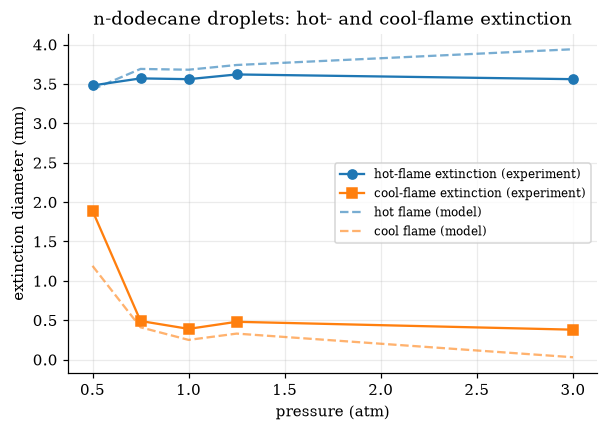

CFI tests: 87 | fuels: {'[.60]/[.40] C12H26/iso-dodecane': 41, '[.75]/[.25] C12H26/iso-dodecane': 24, 'C12H26': 22}
CIR id agreement table vs test sheet: {nan: 75, True: 12}


In [22]:
c12 = pd.read_csv(PROC / "psi117_proci_2023_c12_extinction_diameter_vs_pressure.csv", encoding="latin-1")
c12.columns = [c.strip("﻿").strip("ï»¿") for c in c12.columns]
pcol = c12.columns[0]
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.plot(c12[pcol], c12["Dext_HF_EXPT"], "o-", label="hot-flame extinction (experiment)")
ax.plot(c12[pcol], c12["Dext_CF_EXPT"], "s-", label="cool-flame extinction (experiment)")
ax.plot(c12[pcol], c12["Dext_HF_model"], "--", color="C0", alpha=.6, label="hot flame (model)")
ax.plot(c12[pcol], c12["Dext_CF_Model"], "--", color="C1", alpha=.6, label="cool flame (model)")
ax.set_xlabel("pressure (atm)"); ax.set_ylabel("extinction diameter (mm)"); ax.legend(fontsize=8)
ax.set_title("n-dodecane droplets: hot- and cool-flame extinction")
savefig(fig, "fig11_c12_extinction",
        "Figure 11. n-Dodecane droplet extinction diameters for hot and cool flames versus pressure, experiment and model, "
        "as provided in PSI-117 analysed data (PROCI 2023). Source: PSI-117. Unit: experimental condition (values as published).")
cfi = load("cfi_tests")
print("CFI tests:", len(cfi), "| fuels:", cfi.fuel.value_counts().head(6).to_dict())
print("CIR id agreement table vs test sheet:", cfi.cir_match.value_counts(dropna=False).to_dict())

Cool flames (low-temperature chemistry, ≈600–800 K) persist to much smaller droplet sizes than hot flames and depend
strongly on pressure. In microgravity they can survive after hot-flame extinction for liquid hydrocarbons such as heptane
and dodecane — the mechanism behind Section 4.

## 9. Case E — Where the experiments sit relative to exploration atmospheres

Unit: one test (FLEX, CFI, ACME CFI-G and Flame Design, BASS-II, Saffire). Reference atmospheres are taken from
NTRS 20260002050 (Artemis surface-vehicle atmosphere options) and the ISS nominal cabin.

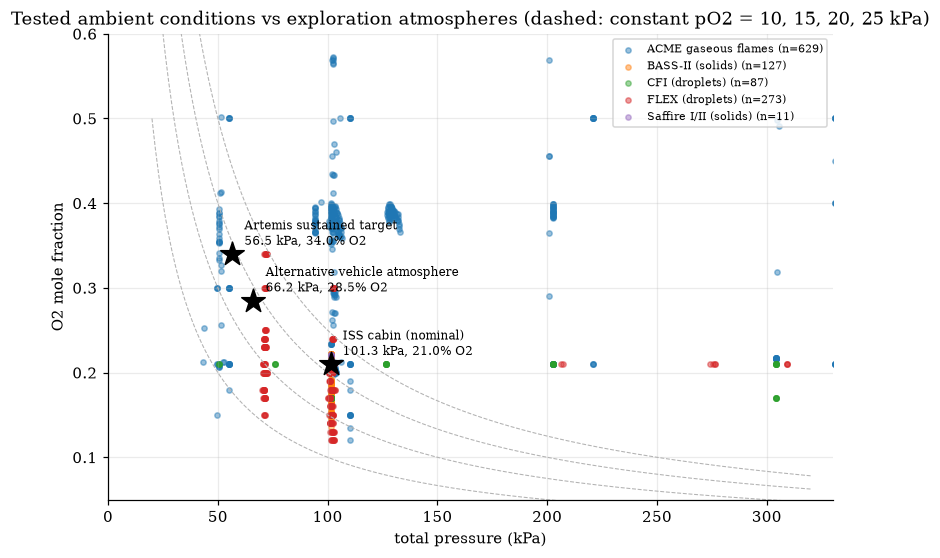

atmosphere             Alternative vehicle atmosphere  Artemis sustained target  ISS cabin (nominal)
family                                                                                              
ACME gaseous flames                                 0                        13                  116
BASS-II (solids)                                    0                         0                   68
CFI (droplets)                                      0                         0                   28
FLEX (droplets)                                     8                         0                   90
Saffire I/II (solids)                               0                         0                   11


In [23]:
pts = []
pts += [("FLEX (droplets)", r.p_kPa, r.x_o2) for r in f.itertuples()]
pts += [("CFI (droplets)", r.p_atm * 101.325, r.x_o2) for r in cfi.dropna(subset=["p_atm", "x_o2"]).itertuples()]
for nm, xcol, pcol, fac in [("table_PSI-159_cfi_g_normal_flames", "XO2 before test", "approx p (bar)", 100),
                            ("table_PSI-159_cfi_g_inverse_flames", "XO2", "approx p (bar)", 100),
                            ("table_PSI-10_flame_design_normal_flame", "XO2 (init)", "pmean (atm)", 101.325),
                            ("table_PSI-10_flame_design_inverse_flame", "XO2", "pmean (atm)", 101.325)]:
    d = load(nm)
    x = pd.to_numeric(d[xcol], errors="coerce"); p = pd.to_numeric(d[pcol], errors="coerce") * fac
    pts += [("ACME gaseous flames", pi, xi) for pi, xi in zip(p, x) if np.isfinite(pi) and np.isfinite(xi)]
pts += [("BASS-II (solids)", 101.3, r.o2_init_pct / 100) for r in ok.dropna(subset=["o2_init_pct"]).itertuples()]
pts += [("Saffire I/II (solids)", 101.3, r.o2_pct / 100) for r in saf.dropna(subset=["o2_pct"]).itertuples()]
P = pd.DataFrame(pts, columns=["family", "p_kPa", "x_o2"])
P = P[(P.x_o2 > 0) & (P.x_o2 < 1) & (P.p_kPa > 0)]
ref = pd.DataFrame([("ISS cabin (nominal)", 101.3, 0.21), ("Artemis sustained target", 56.5, 0.34),
                    ("Alternative vehicle atmosphere", 66.2, 0.285)], columns=["atmosphere", "p_kPa", "x_o2"])
ref["pO2_kPa"] = ref.p_kPa * ref.x_o2
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i, (fam, g) in enumerate(P.groupby("family")):
    ax.scatter(g.p_kPa, g.x_o2, s=12, alpha=.45, label=f"{fam} (n={len(g)})", color=plt.cm.tab10(i))
for r in ref.itertuples():
    ax.scatter(r.p_kPa, r.x_o2, marker="*", s=260, color="k", zorder=5)
    ax.annotate(f"{r.atmosphere}\n{r.p_kPa} kPa, {r.x_o2*100:.1f}% O2", (r.p_kPa, r.x_o2), xytext=(8, 6),
                textcoords="offset points", fontsize=8)
pp = np.linspace(20, 320, 200)
for po2 in [10, 15, 20, 25]:
    ax.plot(pp, po2 / pp, color="0.7", lw=.7, ls="--")
ax.set_xlim(0, 330); ax.set_ylim(0.05, 0.6)
ax.set_xlabel("total pressure (kPa)"); ax.set_ylabel("O2 mole fraction"); ax.legend(fontsize=7, loc="upper right")
ax.set_title("Tested ambient conditions vs exploration atmospheres (dashed: constant pO2 = 10, 15, 20, 25 kPa)")
savefig(fig, "fig12_conditions_vs_exploration_atmospheres",
        "Figure 12. Ambient pressure and O2 mole fraction of individual PSI combustion tests versus proposed exploration "
        "atmospheres (stars; NTRS 20260002050) and the ISS cabin. Unit: test.")
def nearest(fam_mask, p0, x0):
    d = P[fam_mask]
    dist = np.hypot((d.p_kPa - p0) / 101.325, (d.x_o2 - x0) / 0.21)
    return d.loc[dist.idxmin()], dist.min()
rows = []
for r in ref.itertuples():
    for fam in P.family.unique():
        n, dmin = nearest(P.family == fam, r.p_kPa, r.x_o2)
        within = ((P.family == fam) & ((P.p_kPa - r.p_kPa).abs() <= 10) & ((P.x_o2 - r.x_o2).abs() <= 0.03)).sum()
        rows.append({"atmosphere": r.atmosphere, "family": fam, "tests_within_10kPa_3pctO2": int(within),
                     "nearest_p_kPa": round(n.p_kPa, 1), "nearest_x_o2": round(n.x_o2, 3)})
cov = pd.DataFrame(rows); cov.to_csv(TAB / "T08_coverage_of_exploration_atmospheres.csv", index=False)
print(cov.pivot(index="family", columns="atmosphere", values="tests_within_10kPa_3pctO2"))

**Finding.** Solid-material experiments with flight data in PSI (Saffire, BASS-II) were all run at ISS cabin pressure
and ≤22% O₂. No PSI solid-fuel test sits near the Artemis target of 56.5 kPa / 34% O₂ or the 66.2 kPa / 28.5% option.
Some droplet and gaseous-flame tests reach comparable O₂ fractions or partial pressures, but for liquid or gaseous fuels,
whose flammability does not transfer directly to cabin solids. This is the single most important evidence gap for
lunar-habitat fire safety, and it is the gap SoFIE and the Flammability of Materials on the Moon experiment were designed
to close (NTRS 20200000361, 20240008623).

### 9.1 Evidence coverage matrix for engineering decisions

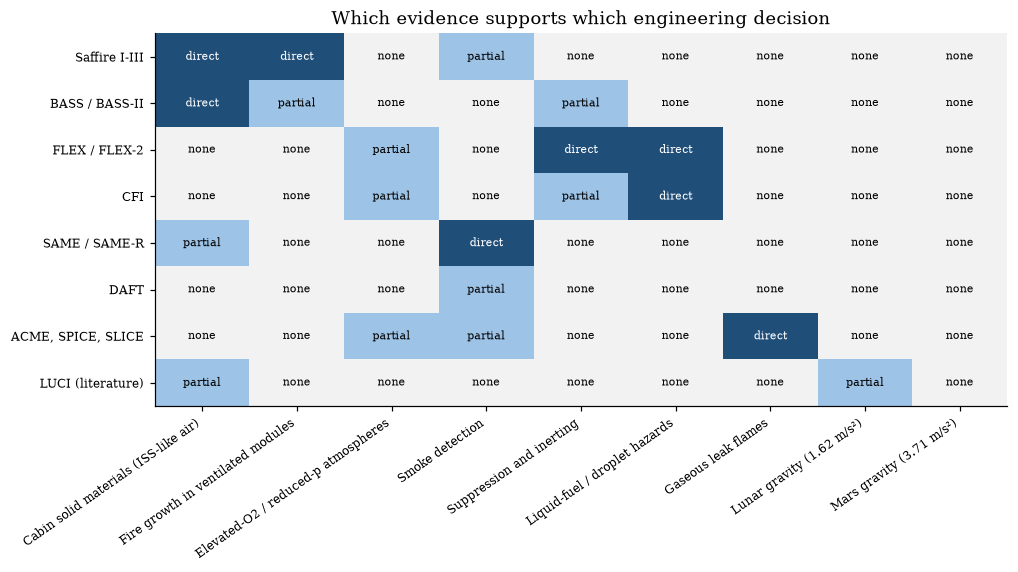

In [24]:
domains = ["Cabin solid materials (ISS-like air)", "Fire growth in ventilated modules", "Elevated-O2 / reduced-p atmospheres",
           "Smoke detection", "Suppression and inerting", "Liquid-fuel / droplet hazards", "Gaseous leak flames",
           "Lunar gravity (1.62 m/s²)", "Mars gravity (3.71 m/s²)"]
# 2 = direct measurement in the regime; 1 = partial / proxy (different regime, conditions only, or literature only); 0 = none
E = {
 "Saffire I-III": [2, 2, 0, 1, 0, 0, 0, 0, 0],
 "BASS / BASS-II": [2, 1, 0, 0, 1, 0, 0, 0, 0],
 "FLEX / FLEX-2": [0, 0, 1, 0, 2, 2, 0, 0, 0],
 "CFI": [0, 0, 1, 0, 1, 2, 0, 0, 0],
 "SAME / SAME-R": [1, 0, 0, 2, 0, 0, 0, 0, 0],
 "DAFT": [0, 0, 0, 1, 0, 0, 0, 0, 0],
 "ACME, SPICE, SLICE": [0, 0, 1, 1, 0, 0, 2, 0, 0],
 "LUCI (literature)": [1, 0, 0, 0, 0, 0, 0, 1, 0],
}
EM = pd.DataFrame(E, index=domains).T
EM.to_csv(TAB / "T09_evidence_coverage_matrix.csv")
fig, ax = plt.subplots(figsize=(10, 4.4))
cmap = matplotlib.colors.ListedColormap(["#f2f2f2", "#9dc3e6", "#1f4e79"])
ax.imshow(EM.values, cmap=cmap, vmin=0, vmax=2, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(domains))); ax.set_xticklabels(domains, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(EM))); ax.set_yticklabels(EM.index, fontsize=8)
for i in range(EM.shape[0]):
    for j in range(EM.shape[1]):
        ax.text(j, i, ["none", "partial", "direct"][EM.values[i, j]], ha="center", va="center", fontsize=7,
                color="white" if EM.values[i, j] == 2 else "black")
ax.set_title("Which evidence supports which engineering decision")
savefig(fig, "fig13_evidence_matrix",
        "Figure 13. Coded evidence coverage. 'Direct' = measured in the regime the decision concerns; 'partial' = related "
        "measurement in a different regime, conditions only, or literature-only result; 'none' = no relevant data. "
        "Coding rules are documented in SCIENTIFIC_METHODS.md. Mars gravity has no test data in any source examined.")

The matrix is a qualitative coding, not a score. Its purpose is to stop interpolation: lunar and Martian fire behaviour
cannot be obtained by interpolating between 1 g and orbital microgravity, because flame spread is non-monotonic in
gravity (LUCI measured *slower* downward spread over SIBAL in simulated lunar gravity than in 1 g, while FM² cites
materials that are *more* flammable at lunar gravity). AeroFox labels any lunar or Martian statement as conditional on
this sparse evidence.

## 10. Scientific findings catalog

Each finding below is generated from the computations above and written to `data/findings/findings.json`, which the
AeroFox agent loads as first-class evidence.

In [25]:
reg_m = reg[(reg.fuel == "Methanol")].set_index("term"); reg_h = reg[(reg.fuel == "Heptane")].set_index("term")
lit = json.loads((DATA / "curated" / "literature_evidence.json").read_text())
findings = [
 dict(id="F01", question="Is the FLEX experiment table internally consistent with the per-test files?",
      result=f"The PSI table's 'FLEX Test #' differs from official FLEX numbering for {int((flex.table_number_offset != 0).sum())} of {len(flex)} rows (offset 1-6). Matching on the CIR identifier restores agreement: refitted K vs tabulated K r = {r_ok:.3f} (n={len(v)}) versus r = {r_naive:.3f} with the table numbering.",
      dataset="PSI-69 experiment table, TestSheet and DropletData files; NASA/TP-2015-216046", locator="flex_tests.csv columns flex_number, table_number_offset; Figure 4",
      conditions="All FLEX tests 2009-2012", method="CIR-id join; OLS of d^2 vs t on 0.2-0.9 tb", uncertainty=f"IQR of K difference [{diff.quantile(.25):+.3f}, {diff.quantile(.75):+.3f}] mm^2/s",
      limitations="Tests without CIR id or with duplicate CIR id keep the table number.", implication="Any reuse of the FLEX table must join on CIR id.",
      applicability="Data engineering for FLEX", feature="dataset integrity check; experiment lookup by official number", evidence_type="measured"),
 dict(id="F02", question="Can the published FLEX burning-rate constants be reproduced from raw droplet histories?",
      result=f"Yes: median difference {diff.median():+.4f} mm^2/s, IQR [{diff.quantile(.25):+.4f}, {diff.quantile(.75):+.4f}] across {len(v)} tests with R^2>0.95.",
      dataset="PSI-69 DropletData files", locator="flex_droplet_fits.csv; Figure 4", conditions="Methanol and heptane, 0.5-3 atm",
      method="OLS d^2 = a - K t on 0.2-0.9 of tabulated burn time", uncertainty="Fit SE per test in flex_droplet_fits.csv",
      limitations="Window choice affects K for short burns (tb < 2 s).", implication="Tabulated K can be used with confidence once correctly keyed.",
      applicability="Droplet combustion, microgravity", feature="burning-rate tool", evidence_type="measured"),
 dict(id="F03", question="How does K depend on O2 and diluent in FLEX?",
      result=f"Per 0.1 increase in X_O2, K rises by {0.1*reg_m.loc['X_O2','coef']:.3f} mm^2/s (methanol, 95% CI {0.1*reg_m.loc['X_O2','ci95_lo']:.3f}-{0.1*reg_m.loc['X_O2','ci95_hi']:.3f}) and {0.1*reg_h.loc['X_O2','coef']:.3f} mm^2/s (heptane, CI {0.1*reg_h.loc['X_O2','ci95_lo']:.3f}-{0.1*reg_h.loc['X_O2','ci95_hi']:.3f}), holding pressure and diluent fixed. Helium vs N2 shift: methanol {reg_m.loc['He vs N2','coef']:+.3f}, heptane {reg_h.loc['He vs N2','coef']:+.3f} mm^2/s.",
      dataset="PSI-69 table", locator="Table T05; Figure 5", conditions="Microgravity, 0.5-3 atm, X_O2 0.12-0.34",
      method="OLS with bootstrap (2000 resamples of tests)", uncertainty="Bootstrap 95% CI; measurement error in K not reported",
      limitations="Non-factorial design; droplet size pooled; descriptive model only.", implication="Higher O2 increases burning rate of liquid fuels; He diluent does not slow burning.",
      applicability="Liquid fuels in microgravity only", feature="what-if O2 comparison for droplets", evidence_type="model_of_measurements"),
 dict(id="F04", question="Does combustion stop when the visible flame goes out (FLEX-035)?",
      result=f"No. After visible extinction at {FLEX035['tb']:.1f} s the droplet regresses at {FLEX035['K_p']:.3f}±{FLEX035['se_p']:.3f} mm^2/s versus {FLEX035['K_b']:.3f}±{FLEX035['se_b']:.3f} while burning (ratio {FLEX035['ratio']:.2f}); regression stalls about {FLEX035['plateau_t']-FLEX035['tb']:.0f} s later. The FLEX report attributes this to cool-flame burning.",
      dataset="PSI-69 FLEX-035 DropletData and LLUVData; NASA/TP-2015-216046 Fig. 39", locator="Figure 7",
      conditions="Heptane, air, 102.4 kPa, microgravity", method="OLS on d^2 before/after tabulated extinction time",
      uncertainty="Standard errors of fitted slopes; extinction time from table", limitations="One test; cool flame inferred from literature, not measured here.",
      implication="Optical flame-out is not a reliable end-of-event signal for hydrocarbon liquid fires in microgravity.",
      applicability="Hydrocarbon droplets, microgravity, near-atmospheric pressure", feature="FLEX-035 case study; detection caveats", evidence_type="measured + published interpretation"),
 dict(id="F05", question="Were Saffire-II samples 2-5 and 2-6 tested at the same flow?",
      result=f"No. Telemetry gives {SAF['flow5']:.1f} cm/s for 2-5 and {SAF['flow6']:.1f} cm/s for 2-6 (table: 20 for both; NTRS: 25 for 2-6). Spread rates {SAF['v5']} and {SAF['v6']} mm/s.",
      dataset="PSI-99 telemetry workbook; PSI-99 table; NTRS 20170008805", locator="Table T06; Figure 8",
      conditions="Cygnus, ~22% O2, concurrent flow, cotton-fiberglass fabric 5 x 29 cm", method="Mean of two anemometers over 120 s after ignition",
      uncertainty="Anemometer SD within window <0.1 cm/s; inter-anemometer difference up to 3 cm/s (sample 2-9)", limitations="Single sample per flow; no spread-rate uncertainty.",
      implication="Use measured flow (25 cm/s) for 2-6 in any model validation.", applicability="Concurrent spread over thin fabric in microgravity",
      feature="Saffire comparison tool", evidence_type="measured"),
 dict(id="F06", question="Did materials that burn in 1-g screening burn in microgravity Saffire-II?",
      result="Silicone sheets 0.27 and 0.61 mm thick, which burn completely or partially in 1-g upward tests, did not propagate in Saffire-II at 20 cm/s and ~22% O2 (table: insignificant burn).",
      dataset="PSI-99 table; NTRS 20170008805", locator="saffire_samples.csv rows 2-1..2-4", conditions="Microgravity, 20 cm/s, ~22% O2",
      method="Tabulated outcomes", uncertainty="Qualitative outcome", limitations="One flow speed and O2 level; result may not hold at higher flow or O2.",
      implication="For these conditions 1-g upward screening was conservative for silicone.", applicability="Thin silicone sheets, ISS-like air",
      feature="materials comparison", evidence_type="measured"),
 dict(id="F07", question="What smoke particle sizes must spacecraft detectors see?",
      result="SAME-R median arithmetic mean diameters: " + ", ".join(f"{m} {same_tab.loc[('SAME-R', m), 'AMD_median_um']:.2f} µm" for m in mats) + ".",
      dataset="PSI-101 results workbook", locator="Table T07; Figure 10", conditions="Overheated (non-flaming) materials, microgravity, aging 11-1800 s",
      method="Group medians of per-test M1/M0", uncertainty="IQR per material in Table T07", limitations="Non-flaming smoke only; instrument-specific moments.",
      implication="Detectors must respond to sub-micrometre particles; particle size depends on material and transport time.",
      applicability="Smoke detection in pressurised modules", feature="detection evidence card", evidence_type="measured"),
 dict(id="F08", question="Can detector alarm performance be inferred from SAME-R?",
      result=f"Not from the PSI tables: the ISS scatter channel is at or above 6.2 V in {100*SAME['sat']:.0f}% of {SAME['n']} SAME-R tests, consistent with range saturation; no alarm thresholds or times are recorded.",
      dataset="PSI-101 results workbook", locator="same_r_detectors.csv", conditions="SAME-R", method="Distribution of detector voltage",
      uncertainty="n/a", limitations="Saturation inferred from value clustering, not from instrument documentation.",
      implication="AeroFox must not claim detector response times from these data.", applicability="Detection", feature="limitation statement", evidence_type="measured"),
 dict(id="F09", question="Do PSI solid-material tests cover exploration atmospheres?",
      result="No PSI solid-fuel flight test lies within 10 kPa and 3 percentage points O2 of 56.5 kPa/34% or 66.2 kPa/28.5%; all Saffire and BASS-II tests were at ~101 kPa and <=22.2% O2. The closest liquid-fuel data are FLEX droplet tests near 72 kPa and X_O2 = 0.34, and ACME gaseous flames near 50-55 kPa with X_O2 0.3-0.4, which do not transfer to cabin solids.",
      dataset="PSI tables; NTRS 20260002050", locator="Table T08; Figure 12", conditions="as tabulated", method="Nearest-condition search",
      uncertainty="n/a", limitations="Literature-only data (e.g. ground NASA-STD-6001 tests) not included.",
      implication="Lunar-habitat material decisions at elevated O2 need ground testing at the target atmosphere and SoFIE/FM2 results.",
      applicability="Lunar/Mars habitat atmosphere selection", feature="atmosphere-applicability tool", evidence_type="measured coverage + published atmosphere"),
 dict(id="F10", question="Can lunar-gravity fire behaviour be interpolated between 1 g and microgravity?",
      result="No. In simulated lunar gravity (LUCI) downward spread over SIBAL was 0.6x (flame base) and 0.39x (flame tip) the 1-g rate, while FM2 reports materials more flammable at lunar gravity than in 1 g.",
      dataset="NTRS 20250010653, 20240008623", locator="LUCI combined results slide; FM2 abstract", conditions="Simulated lunar g, air, 1 atm",
      method="Published measurements", uncertainty="Not reported", limitations="Short duration, rotating platform, Coriolis effects.",
      implication="Treat lunar and Martian fire behaviour as unknown unless tested; do not interpolate.", applicability="Partial gravity",
      feature="gravity-regime guardrail", evidence_type="published measurement"),
 dict(id="F11", question="What drives radiative extinction of droplets?",
      result="Extinction diameter as a fraction of initial diameter increases as X_O2 decreases (Spearman rho " +
             ", ".join(f"{k} {v:.2f}" for k, v in e.groupby('fuel').apply(lambda g: g.x_o2.corr(g.dext_over_d0, method='spearman')).items()) + ").",
      dataset="PSI-69 table", locator="Figure 6", conditions="FLEX extinction tests", method="Spearman rank correlation",
      uncertainty="n/a", limitations="Mixed pressures and diluents.", implication="Large fuel volumes in low O2 may self-extinguish early, but cool flames can persist.",
      applicability="Droplets, microgravity", feature="extinction explanation", evidence_type="measured"),
 dict(id="F12", question="How much of the PSI combustion archive is analysis-ready?",
      result=f"{dlog['catalog']['entries']:,} catalog entries ({dlog['catalog']['referenced_bytes']/1e12:.2f} TB). AeroFox's verified snapshot uses {sum(p.stat().st_size for p in (DATA/'raw').rglob('*') if p.is_file())/1e6:.0f} MB: {len(list((DATA/'raw'/'psi'/'tables').glob('*/*.csv')))} experiment tables, {len(list((DATA/'raw'/'psi'/'files'/'PSI-69').glob('*DropletData.txt')))} FLEX droplet histories, {len(list((DATA/'raw'/'psi'/'files'/'PSI-69').glob('*TestSheet.txt')))} FLEX test sheets, CFI files and reduced aerosol data.",
      dataset="PSI catalog", locator="Figure 1; Table T01", conditions="n/a", method="Catalog enumeration",
      uncertainty="n/a", limitations="Video and image archives not analysed.", implication="Offline operation is feasible.",
      applicability="Data engineering", feature="offline snapshot", evidence_type="measured"),
]
(DATA / "findings").mkdir(exist_ok=True)
(DATA / "findings" / "findings.json").write_text(json.dumps({"generated_by": "notebooks/AeroFox_Comprehensive_Data_Analysis.ipynb",
    "findings": findings, "figures": FIGS}, indent=1, default=float))
pd.DataFrame(findings)[["id", "question", "result", "evidence_type"]].to_csv(TAB / "T10_findings_catalog.csv", index=False)
for fnd in findings: print(f"{fnd['id']}: {fnd['result']}\n")

F01: The PSI table's 'FLEX Test #' differs from official FLEX numbering for 119 of 274 rows (offset 1-6). Matching on the CIR identifier restores agreement: refitted K vs tabulated K r = 0.987 (n=206) versus r = 0.729 with the table numbering.

F02: Yes: median difference -0.0011 mm^2/s, IQR [-0.0069, +0.0069] across 206 tests with R^2>0.95.

F03: Per 0.1 increase in X_O2, K rises by 0.162 mm^2/s (methanol, 95% CI 0.142-0.183) and 0.192 mm^2/s (heptane, CI 0.117-0.257), holding pressure and diluent fixed. Helium vs N2 shift: methanol +0.144, heptane +0.144 mm^2/s.

F04: No. After visible extinction at 8.9 s the droplet regresses at 0.419±0.003 mm^2/s versus 0.412±0.004 while burning (ratio 1.02); regression stalls about 27 s later. The FLEX report attributes this to cool-flame burning.

F05: No. Telemetry gives 20.0 cm/s for 2-5 and 25.0 cm/s for 2-6 (table: 20 for both; NTRS: 25 for 2-6). Spread rates 2.1 and 2.6 mm/s.

F06: Silicone sheets 0.27 and 0.61 mm thick, which burn completel

## 11. What these findings mean for the AeroFox architecture

| Observation from the data | Consequence for the agent |
|---|---|
| The archive is large, but the analysis-ready evidence is ~40 MB | Ship a complete, versioned offline snapshot; never query PSI at answer time |
| Record-linkage errors exist inside official tables (FLEX numbering, Saffire-II flow) | Retrieval must return the corrected record *and* the discrepancy; numbers come from processed tables, not from model memory |
| Quantities have different status (measured, derived, published, inferred) | Every number in an answer carries an evidence type and a locator |
| Evidence covers ISS-like air and microgravity well, exploration atmospheres and partial gravity poorly | Applicability scoring by pressure, O₂, gravity, fuel type; explicit "no direct evidence" answers |
| Many engineering questions have no defensible quantitative ranking | Charts of evidence coverage and decision matrices instead of invented risk scores |
| Simple, verifiable physics (d²-law, well-mixed transport) reproduces measured behaviour | Deterministic tools for calculations; the language model chooses tools and explains results, it does not compute |

## 12. Reproducibility record

In [26]:
import platform
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print("Figures written:", len(FIGS)); print("Tables written:", len(list(TAB.glob('*.csv'))))
(ROOT / "outputs" / "figure_captions.json").write_text(json.dumps(FIGS, indent=1))

Python 3.12.14 | pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2
Figures written: 13
Tables written: 10


4094